# 配对状态 v5：高斯 HMM（连续变量，不分格），轨迹平滑 11 帧

2026-11-08 讨论后，在网格方法（v3、v4）之外试 HMM。思路：
- **输入是连续值，不分格**：14 个变量全部进入（v3 的 `D_xy, Δz, θ_a, θ_b, speed_a, speed_b` + v4 的 `bearing_rate, approach, turn_a/b, bend_a/b, pitch_a/b`），变成 16 个特征（距离取 log，带符号的量取带符号 log，角度取 cos/sin，速度和角速度取 log10，弯曲和俯仰原值），用训练集标准化。contact 帧（角度无定义）的 cos/sin = 0、角速度 = 训练集中位数，留在序列里（不丢）。只缺尾点等其他未定义的帧没有状态（同 v4）。
- **HMM 只用训练集拟合，不看标注**：每个隐藏状态 = 一种典型的"配对姿态 + 运动"（一个 16 维高斯），状态之间有转移概率。实现：`scripts/analysis/pair_hmm.py` 的 `TorchGaussianHMM`（torch，GPU；单元测试里和 hmmlearn 的似然、Viterbi 完全一致）。
- **两种用法**（你选"都试"）：
  - **小 K**：K ∈ `K_SMALL`，HMM 状态直接当行为状态。K 用只看训练集的规则选：留一实验交叉验证的 AUC（同 v3 选 τ 的方法）；同时报告 BIC 和留出数据的似然。
  - **大 K + Infomap**：K = `K_LARGE`，HMM 状态当微状态（代替网格），在其上建 lag-τ 转移矩阵、跑 Infomap（同论文流程），τ 同样按训练集规则选。
- **评估和 v3 完全相同**：训练集估计 P(类别 | 状态或簇)，平滑，训练集定阈值，测试集（K_1_3、P_1_3）上算 AUC、AP、精确率、召回率、bout，按视频三分类（qc / att / other），FM1 / FM2 方向，并和**距离基线**比较；最后和 v3 的结果放在一张表里。

训练 = K_1_1、K_1_2、P_1_1、P_1_2；测试 = K_1_3、P_1_3（同一批鱼）。标注规则同 v3（qc / att / wrap，其余 unknown），只在 HMM 拟合之后使用。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261108_pair_hmm_sw11_v5/`。本 notebook 只给数值和图，不下结论。

## 参数

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261108_pair_hmm_sw11_v5"
OUTPUT_ROOT = None
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
FPS_NOMINAL = 166.0
DPI = 200
THUMB_WIDTH = 900

# --- variables (same definitions as v3 / v4)
MIN_XY_MM = 1.0
SPEED_HALF_WINDOW = 3
SMOOTH_WINDOW = 11
SG_ORDER = 2

# --- HMM
K_SMALL = [10, 20, 40, 60]
K_LARGE = 100
FIT_FRACTION = 0.35      # share of train segments (chosen at random) used to fit; another HOLDOUT_FRACTION for held-out likelihood
HOLDOUT_FRACTION = 0.15
N_ITER = 80
TOL_PER_FRAME = 1e-4     # stop when the log-likelihood gain per fitted frame is below this
HMM_SEED = 20261108
WINDOW = 512             # sequence pieces for the GPU recursions (frames)
DEVICE = "cuda"          # falls back to cpu if CUDA is not available

# --- Infomap on the K_LARGE states
TAU_SCAN = [1, 3, 7, 17, 30, 50, 100]
N_TRIALS = 200
INFOMAP_SEED = 20261107
KEEP_SELF_LOOPS = True

# --- labels and scoring (same as v3)
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "qc": ["quick circle", "incomplete qc", "courtship"],
    "att": ["attack", "attempted att", "dash"],
}
DETECT_CLASSES = ["qc", "att", "wrap"]
DURATION_S = {"qc": (0.75, 4.0), "att": (5 / FPS_NOMINAL, 0.75), "wrap": (0.75, None)}
SMOOTH_FRAMES = {c: max(1, int(round(lo * FPS_NOMINAL))) for c, (lo, _hi) in DURATION_S.items()}
PRIOR_FRAMES = 50.0
MIN_POS = 100
THREE_CLASS = {"FM": ["qc", "att"], "MM": ["qc", "att"]}
TRUTH_ROWS = ["qc", "att", "wrap", "none"]
SELECT_CLASS = {"FM": "qc", "MM": "att"}   # class whose train LOEO-AUC picks K (small) and tau (large)
DIST_BIN_MM = 2.0
DIST_MAX_MM = 300.0
V3_RUN = "20261108_pair_state6d_speed_v3"   # for the comparison table (read only)

# --- ethograms: (experiment, class, unit, window seconds)
ETHOGRAM_SPECS = [("20251225_K_1_3_FCMC", "qc", "FM", 30.0), ("20260112_P_1_3_FCMC", "qc", "FM", 30.0),
                  ("20251225_K_1_3_FCMC", "att", "MM", 10.0), ("20260112_P_1_3_FCMC", "att", "MM", 10.0)]

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}")

38 parameters; run 20261108_pair_hmm_sw11_v5


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录；定义打分函数（和 v3 Step 5 相同）。`pair_hmm` 要在 scikit-learn 之前导入（Windows 上 torch 晚导入会失败）。

In [2]:
import os
import sys
import json
import time
import platform
import importlib

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import pair_hmm as H   # imports torch first
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, display
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
ALL_EXPERIMENTS = list(TRAIN_EXPERIMENTS) + list(TEST_EXPERIMENTS)
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}
DEV = DEVICE if (DEVICE == "cpu" or torch.cuda.is_available()) else "cpu"


def _allow_listed(experiment, final):
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed
INFOMAP = S.resolve_infomap_backend()
L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"), "output_dir": str(L.root),
                        "device": DEV, "torch": torch.__version__, "infomap": INFOMAP,
                        "review_root": str(REVIEW_ROOT), "paths_config": str(_CONFIG), "platform": platform.platform()})

VARS = list(H.VARIABLES)    # 14 columns
ANGLE_VARS = ["theta_a", "theta_b", "bearing_rate", "turn_a", "turn_b"]
PRE = {"sw": SMOOTH_WINDOW, "rhw": SPEED_HALF_WINDOW}
CLASS_COLOR = {"wrap": "#d62728", "qc": "#ff7f0e", "att": "#7f3c8d", "unknown": "#c7c7c7", "none": "#ffffff"}
METHOD_COLOR = {"hmm_small": "#1f77b4", "hmm_large_states": "#9467bd", "hmm_large_infomap": "#d62728", "distance": "#2f7f7f"}


def copy_name(a, b):
    return f"{a}{b}"


COPIES = {u: [copy_name(a, b) for a, b in pairs] for u, pairs in UNITS.items()}
COPY_PAIR = {copy_name(a, b): (a, b) for pairs in UNITS.values() for a, b in pairs}
PAIR_COPIES = ["FM1", "FM2", "M1M2"]


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def with_nostate(states, n):
    # ids for scoring: frames without a state -> one extra pseudo id n
    return np.where(states >= 0, states, n).astype(np.int64), n + 1


def fit_scores(ids, y, n_ids):
    sc = P4.cluster_scores(ids, y, n_ids, PRIOR_FRAMES)
    ok = (y >= 0) & (ids >= 0)
    return sc, (float(y[ok].mean()) if ok.any() else 0.0)


def loeo_scores(ids, y, exp, block, n_ids, window):
    s = np.full(len(ids), np.nan)
    for ei in np.unique(exp):
        fit = exp != ei
        sc, base = fit_scores(np.where(fit, ids, -1), np.where(fit, y, -1), n_ids)
        m = exp == ei
        s[m] = P4.frame_scores(ids[m], sc, base)
    return P4.rolling_mean_blocks(s, block, window)


def safe_auc(y, s, mask=None):
    ok = (y >= 0) & np.isfinite(s) if mask is None else (y >= 0) & np.isfinite(s) & mask
    if (y[ok] == 1).sum() < 1 or (y[ok] == 0).sum() == 0:
        return np.nan
    return float(roc_auc_score(y[ok], s[ok]))


def mmss(seconds):
    return f"{int(seconds // 60):02d}:{seconds % 60:05.2f}"


print("output folder", L.root, "| device", DEV, "| infomap", INFOMAP)

output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_hmm_sw11_v5 | device cuda | infomap {'backend': 'python-igraph', 'version': '1.0.0', 'call': "Graph.community_infomap(edge_weights='weight', trials=N)", 'seed_note': "community_infomap has no seed argument; igraph uses Python's random module, which is seeded before every call"}


## Step 0 — 读数据、平滑、14 个变量、BORIS 标注、缺口统计

**做什么**：同 v4 Step 0（平滑 `SMOOTH_WINDOW` 帧，不丢帧），另加两条鱼的 pec 3D 速度（同 v3）。每帧分类：有状态 / contact / 审核屏蔽 / 跟踪丢失（head 或 pec）/ 其他未定义。BORIS 标注按 v3 Step 2b 的规则。

**输出**：`data/00_gap_table__all__…__all.csv`；变量只在内存里。

In [3]:
# Step 0: variables, labels, gap table.
L.clear_log("00")
DATA, FRAME_LABELS, FPS, gap_rows = {}, {}, {}, []
non_angle = [VARS.index(n) for n in VARS if n not in ANGLE_VARS]
for e in ALL_EXPERIMENTS:
    t0 = time.time()
    tr = M.load_trial(e, final=True)
    nodes = P4.smooth_tracks(np.array(tr["named"], dtype=np.float64), SMOOTH_WINDOW, SG_ORDER)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    frames = np.asarray(tr["frames"], dtype=np.int64)
    FPS[e] = fps = float(tr["fps"])
    speed = np.column_stack([P4.fish_speed(nodes[:, i, P4.PEC], fps, SPEED_HALF_WINDOW) for i in range(3)])
    bouts = M.bouts_of(e)
    for cp, (a, b) in COPY_PAIR.items():
        ia, ib = P4.FISH.index(a), P4.FISH.index(b)
        pa, pb = nodes[:, ia, P4.PEC], nodes[:, ib, P4.PEC]
        v = np.column_stack([P4.pair_variables(nodes, a, b, MIN_XY_MM), speed[:, [ia, ib]],
                             P4.extra_variables(nodes, a, b, fps, SPEED_HALF_WINDOW, MIN_XY_MM)])
        d_xy, dz = np.linalg.norm(pb[:, :2] - pa[:, :2], axis=1), pa[:, 2] - pb[:, 2]
        full = np.isfinite(v).all(axis=1)
        fin_hp = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3)) & ~blocked
        fin = fin_hp & np.isfinite(nodes[:, [ia, ib], P4.TAIL]).all(axis=(1, 2))
        vv = v.copy()
        vv[:, 0], vv[:, 1] = d_xy, dz
        contact = fin & ~full & np.isfinite(vv[:, non_angle]).all(axis=1)
        v[contact, 0], v[contact, 1] = d_xy[contact], dz[contact]
        ok = full | contact
        DATA[(e, cp)] = {"vals": v.astype(np.float32), "contact": contact, "ok": ok, "frames": frames,
                         "d3": np.where(ok, np.linalg.norm(pb - pa, axis=1), np.nan)}
        FRAME_LABELS[(e, cp)] = P4.pair_frame_labels(bouts, a, b, frames, LABEL_CLASSES, directed=True)
        if cp in PAIR_COPIES:
            gap_rows.append({"experiment": exp_short(e), "pair": cp, "with_state_percent": 100 * ok.mean(),
                             "of_which_contact_percent": 100 * contact.mean(), "review_blocked_percent": 100 * blocked.mean(),
                             "tracking_lost_head_or_pec_percent": 100 * (~blocked & ~fin_hp).mean(),
                             "other_undefined_percent": 100 * (fin_hp & ~ok).mean()})
    print(f"{exp_short(e)}: {len(frames)} frames, {time.time() - t0:.0f} s")
GAPS = pd.DataFrame(gap_rows)
L.save_csv(GAPS, "00", "gap_table", "all", PRE, "all")
print(GAPS.round(2).to_string(index=False))


def gather(unit, set_name):
    # concatenated frames of a unit and set, with experiment / copy / block ids and labels
    out = {k: [] for k in ("vals", "contact", "ok", "d3", "exp", "copy", "frame", "label")}
    for ei, e in enumerate(SETS[set_name]):
        for ci, cp in enumerate(COPIES[unit]):
            d = DATA[(e, cp)]
            n = len(d["ok"])
            for k in ("vals", "contact", "ok", "d3"):
                out[k].append(d[k])
            out["exp"].append(np.full(n, ei, np.int16))
            out["copy"].append(np.full(n, ci, np.int8))
            out["frame"].append(d["frames"])
            out["label"].append(FRAME_LABELS[(e, cp)])
    g = {k: np.concatenate(v) for k, v in out.items()}
    g["block"] = g["exp"].astype(np.int64) * 10 + g["copy"]
    g["exp_names"], g["copy_names"] = list(SETS[set_name]), list(COPIES[unit])
    return g


G = {(u, s): gather(u, s) for u in UNITS for s in SETS}
L.log("00", "done")

K_1_1: 348600 frames, 3 s


K_1_2: 348600 frames, 3 s


P_1_1: 348600 frames, 12 s


P_1_2: 348600 frames, 5 s


K_1_3: 348600 frames, 3 s


P_1_3: 348600 frames, 5 s
  csv data/00_gap_table__all__sw11-rhw3__all.csv  rows 18
experiment pair  with_state_percent  of_which_contact_percent  review_blocked_percent  tracking_lost_head_or_pec_percent  other_undefined_percent
     K_1_1  FM1               95.76                      0.61                    3.41                               0.36                     0.47
     K_1_1  FM2               95.42                      0.60                    3.41                               0.19                     0.98
     K_1_1 M1M2               95.11                      0.19                    3.41                               0.42                     1.06
     K_1_2  FM1               93.29                      0.16                    5.97                               0.26                     0.48
     K_1_2  FM2               93.25                      0.10                    5.97                               0.30                     0.48
     K_1_2 M1M2               93.14     

## Step 1 — 特征与 HMM 拟合（只用训练集，不看标注）

**做什么**（每个单元 FM、MM）：
1. 14 个变量 → 16 个特征（`pair_hmm.raw_features`），contact 帧补值（`fill_contact`），用拟合集的均值、标准差标准化。
2. 训练集的连续片段随机分成：拟合集（`FIT_FRACTION`）、留出集（`HOLDOUT_FRACTION`），其余不参与拟合（但之后会解码、打分）。
3. 对每个 K ∈ `K_SMALL` + [`K_LARGE`] 用 EM 拟合（初值 = k-means），记录拟合集对数似然、BIC、留出集每帧对数似然、迭代次数、耗时。

**图** `01_hmm_fit`：左 = 每帧对数似然随 EM 迭代的变化；中 = BIC；右 = 留出集每帧对数似然。

**输出**：`data/01_hmm_fit__all__…__train.csv`、`data/01_hmm_model__<unit>__K<k>…__train.npz`（初始概率、转移矩阵、均值、协方差、特征标准化参数）。

[FM] train frames with a state 2624597; fit 931630 frames in 2336 segments; held out 377542 frames


  K=10: 38 iterations, loglik/frame fit -17.245 held-out -17.548  (1021 s)


  K=20: 80 iterations, loglik/frame fit -15.530 held-out -15.990  (2159 s)


  K=40: 80 iterations, loglik/frame fit -13.832 held-out -14.596  (2181 s)


  K=60: 80 iterations, loglik/frame fit -12.846 held-out -13.835  (2159 s)


  K=100: 80 iterations, loglik/frame fit -11.331 held-out -12.790  (2138 s)


... (3 outputs left out)

  K=40: 80 iterations, loglik/frame fit -14.061 held-out -14.689  (2019 s)


  K=60: 80 iterations, loglik/frame fit -12.937 held-out -13.784  (2043 s)


  K=100: 80 iterations, loglik/frame fit -11.617 held-out -12.965  (1975 s)
  csv data/01_hmm_fit__all__sw11-rhw3__train.csv  rows 10


  fig figures/01_hmm_fit__all__sw11-rhw3__train.png


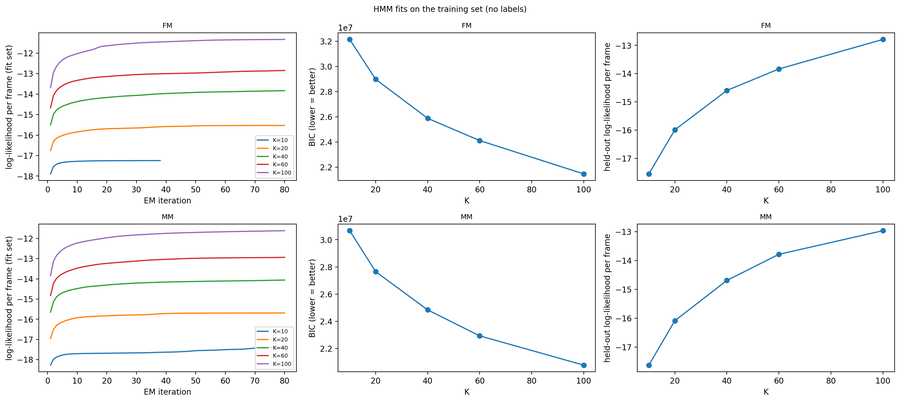

unit   K  fit_frames  iterations  loglik_per_frame_fit          bic  loglik_per_frame_holdout  n_parameters  min_state_occupancy  seconds
  FM  10      931630          38               -17.245 32154424.405                   -17.548          1619                0.066 1021.104
  FM  20      931630          80               -15.530 28983448.617                   -15.990          3439                0.019 2159.124
  FM  40      931630          80               -13.832 25878924.607                   -14.596          7679                0.008 2180.706
  FM  60      931630          80               -12.846 24111072.100                   -13.835         12719                0.005 2158.955
  FM 100      931630          80               -11.331 21459850.406                   -12.790         25199                0.002 2137.544
  MM  10      879736          80               -17.416 30665239.114                   -17.621          1619                0.052 2053.871
  MM  20      879736          80  

In [4]:
# Step 1: features and HMM fits on the training set.
L.clear_log("01")
FEAT, MODELS, fit_rows, HIST = {}, {}, [], {}
for unit in UNITS:
    gt = G[(unit, "train")]
    raw = H.raw_features(gt["vals"])
    noc = gt["ok"] & ~gt["contact"]
    fill = {n: float(np.nanmedian(raw[noc, H.FEATURES.index(n)])) for n in H.ANGLE_RATE_FEATURES}
    s, e_ = H.runs(gt["ok"], gt["block"])
    rng = np.random.default_rng(HMM_SEED)
    u = rng.random(len(s))
    fit_seg, hold_seg = u < FIT_FRACTION, (u >= FIT_FRACTION) & (u < FIT_FRACTION + HOLDOUT_FRACTION)
    idx_fit = np.concatenate([np.arange(a, b) for a, b in zip(s[fit_seg], e_[fit_seg])])
    filled = H.fill_contact(raw[idx_fit], gt["contact"][idx_fit], fill)
    mean, sd = filled.mean(axis=0), filled.std(axis=0)
    FEAT[unit] = {"fill": fill, "mean": mean, "sd": sd}

    def zfeat(g):
        x = H.fill_contact(H.raw_features(g["vals"]), g["contact"], fill)
        x = H.standardise(x, mean, sd)
        x[~g["ok"]] = 0.0
        return x

    FEAT[unit]["z"] = {sn: zfeat(G[(unit, sn)]) for sn in SETS}
    Z = FEAT[unit]["z"]["train"]
    len_fit, len_hold = e_[fit_seg] - s[fit_seg], e_[hold_seg] - s[hold_seg]
    idx_hold = np.concatenate([np.arange(a, b) for a, b in zip(s[hold_seg], e_[hold_seg])])
    print(f"[{unit}] train frames with a state {int(gt['ok'].sum())}; fit {len(idx_fit)} frames in {fit_seg.sum()} segments; "
          f"held out {len(idx_hold)} frames")
    for K in list(K_SMALL) + [K_LARGE]:
        t0 = time.time()
        m = H.TorchGaussianHMM(K, seed=HMM_SEED, device=DEV, window=WINDOW).fit(Z[idx_fit], len_fit, n_iter=N_ITER,
                                                                                 tol_per_frame=TOL_PER_FRAME)
        ll_fit = m.history[-1]
        ll_hold = m.score(Z[idx_hold], len_hold)
        n_par = H.n_parameters(m)
        MODELS[(unit, K)] = m
        HIST[(unit, K)] = np.asarray(m.history) / len(idx_fit)
        fit_rows.append({"unit": unit, "K": K, "fit_frames": len(idx_fit), "iterations": m.n_iter_,
                         "loglik_per_frame_fit": ll_fit / len(idx_fit), "bic": -2 * ll_fit + n_par * np.log(len(idx_fit)),
                         "loglik_per_frame_holdout": ll_hold / len(idx_hold), "n_parameters": n_par,
                         "min_state_occupancy": float(m.startprob_.min()), "seconds": time.time() - t0})
        L.save_npz({"startprob": m.startprob_, "transmat": m.transmat_, "means": m.means_, "covars": m.covars_,
                    "feat_mean": mean, "feat_sd": sd, "features": np.array(H.FEATURES)},
                   "01", "hmm_model", unit, {"K": K, **PRE}, "train", verbose=False)
        print(f"  K={K}: {m.n_iter_} iterations, loglik/frame fit {ll_fit / len(idx_fit):.3f} "
              f"held-out {ll_hold / len(idx_hold):.3f}  ({time.time() - t0:.0f} s)")
FIT = pd.DataFrame(fit_rows)
L.save_csv(FIT, "01", "hmm_fit", "all", PRE, "train")
fig, axes = plt.subplots(len(UNITS), 3, figsize=(16, 3.6 * len(UNITS)), squeeze=False)
for r, unit in enumerate(UNITS):
    d = FIT[FIT["unit"] == unit]
    for K in d["K"]:
        axes[r, 0].plot(np.arange(1, len(HIST[(unit, K)]) + 1), HIST[(unit, K)], label=f"K={K}")
    axes[r, 0].set_xlabel("EM iteration")
    axes[r, 0].set_ylabel("log-likelihood per frame (fit set)")
    axes[r, 0].legend(fontsize=7)
    axes[r, 1].plot(d["K"], d["bic"], "o-")
    axes[r, 1].set_xlabel("K")
    axes[r, 1].set_ylabel("BIC (lower = better)")
    axes[r, 2].plot(d["K"], d["loglik_per_frame_holdout"], "o-")
    axes[r, 2].set_xlabel("K")
    axes[r, 2].set_ylabel("held-out log-likelihood per frame")
    for a in axes[r]:
        a.set_title(unit, fontsize=9)
fig.suptitle("HMM fits on the training set (no labels)", fontsize=10)
fig.tight_layout()
p = L.save_fig(fig, "01", "hmm_fit", "all", PRE, "train")
display(IPImage(filename=str(L.thumbs / p.name)))
print(FIT.round(3).to_string(index=False))
L.log("01", "done")

## Step 2 — 解码：每帧的 HMM 状态（训练、测试）

**做什么**：用每个模型对训练集和测试集的每个连续片段做 Viterbi 解码，得到每帧最可能的状态；没有状态的帧 = −1。MM 另外报告**交换一致率**：M1M2 副本某帧的状态，经"镜像状态"映射（交换 a、b 后最接近的状态均值）后，等于 M2M1 副本同一帧状态的比例（网格方法里这是严格的 1）。

**输出**：`data/02_hmm_states__<unit>__K<k>…__<set>.npz`。

In [5]:
# Step 2: Viterbi decoding of every frame.
L.clear_log("02")
STATES = {}
SWAP_FEAT = []   # feature index permutation and sign flips for the MM swap
_f = list(H.FEATURES)
_perm = list(range(len(_f)))
for a_, b_ in (("cos_theta_a", "cos_theta_b"), ("sin_theta_a", "sin_theta_b"), ("log_speed_a", "log_speed_b"),
               ("log_turn_a", "log_turn_b"), ("bend_a", "bend_b"), ("pitch_a", "pitch_b")):
    i, j = _f.index(a_), _f.index(b_)
    _perm[i], _perm[j] = j, i
_sign = np.ones(len(_f))
_sign[_f.index("slog_dz")] = -1
gen_rows = []
for unit in UNITS:
    for K in list(K_SMALL) + [K_LARGE]:
        m = MODELS[(unit, K)]
        for sn in SETS:
            g = G[(unit, sn)]
            st = H.decode_frames(m, FEAT[unit]["z"][sn], g["ok"], g["block"])
            STATES[(unit, K, sn)] = st
            L.save_npz({"state": st.astype(np.int32)}, "02", "hmm_states", unit, {"K": K, **PRE}, sn, verbose=False)
        row = {"unit": unit, "K": K}
        if unit == "MM":
            mu = m.means_
            # swap in raw feature space: un-standardise, permute / flip, re-standardise
            raw_mu = mu * np.where(FEAT[unit]["sd"] > 0, FEAT[unit]["sd"], 1.0) + FEAT[unit]["mean"]
            sw_mu = (raw_mu[:, _perm] * _sign - FEAT[unit]["mean"]) / np.where(FEAT[unit]["sd"] > 0, FEAT[unit]["sd"], 1.0)
            swap = np.argmin(((sw_mu[:, None, :] - mu[None]) ** 2).sum(-1), axis=1)
            g = G[(unit, "train")]
            st = STATES[(unit, K, "train")]
            a = st[g["copy"] == 0]
            b = st[g["copy"] == 1]
            both = (a >= 0) & (b >= 0)
            row["swap_agreement_train"] = float((swap[a[both]] == b[both]).mean())
            row["self_mirror_states"] = int((swap == np.arange(K)).sum())
        tr_occ = np.bincount(STATES[(unit, K, "train")][STATES[(unit, K, "train")] >= 0], minlength=K)
        te_occ = np.bincount(STATES[(unit, K, "test")][STATES[(unit, K, "test")] >= 0], minlength=K)
        row["states_used_train"] = int((tr_occ > 0).sum())
        row["smallest_state_frames_train"] = int(tr_occ.min())
        row["js_train_test"] = S.js_distance(tr_occ, te_occ)
        dw = []
        for s0, s1 in zip(*H.runs(STATES[(unit, K, "train")] >= 0, G[(unit, "train")]["block"])):
            x = STATES[(unit, K, "train")][s0:s1]
            dw.append(np.diff(np.flatnonzero(np.diff(np.concatenate([[-1], x, [-2]])) != 0)))
        dw = np.concatenate(dw)
        row["median_dwell_s"] = float(np.median(dw) / FPS_NOMINAL)
        gen_rows.append(row)
GEN = pd.DataFrame(gen_rows)
L.save_csv(GEN, "02", "decoding", "all", PRE, "all")
print(GEN.round(3).to_string(index=False))
L.log("02", "done")

  csv data/02_decoding__all__sw11-rhw3__all.csv  rows 10
unit   K  states_used_train  smallest_state_frames_train  js_train_test  median_dwell_s  swap_agreement_train  self_mirror_states
  FM  10                 10                       160207          0.066           0.078                   NaN                 NaN
  FM  20                 20                        63424          0.086           0.096                   NaN                 NaN
  FM  40                 40                        40271          0.108           0.090                   NaN                 NaN
  FM  60                 60                        21372          0.112           0.084                   NaN                 NaN
  FM 100                100                         8804          0.134           0.072                   NaN                 NaN
  MM  10                 10                       189986          0.068           0.078                 0.559                 2.0
  MM  20                 20      

## Step 3 — 小 K：用训练集选 K（留一实验交叉验证）

**做什么**：每个单元、每个 K ∈ `K_SMALL`（以及 K_LARGE 作参照）、每个类别：HMM 状态当簇，用 3 个训练实验估计 P(类别 | 状态)（无状态帧 = 一个伪状态），给第 4 个实验打分，按类别时长下限平滑，四个实验合并算 AUC（同 v3 Step 3a）。距离基线同样流程。**K 的选择**：`SELECT_CLASS`（FM = qc，MM = att）的 LOEO-AUC 最高的 K。只用训练集。

**图** `03_select_k`：LOEO-AUC 随 K；虚线 = 距离基线。

**输出**：`data/03_select_k__all__…__train.csv`。

  csv data/03_select_k__all__sw11-rhw3__train.csv  rows 10


  fig figures/03_select_k__all__sw11-rhw3__train.png


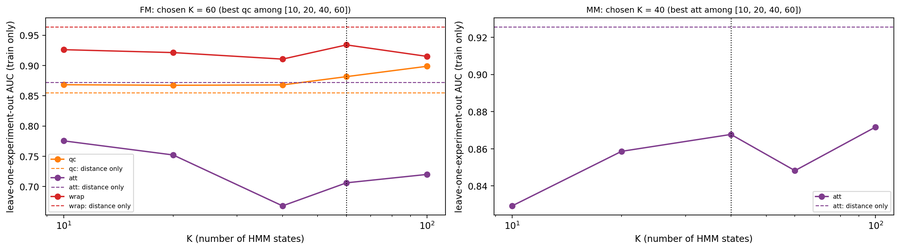

unit   K  loeo_auc_qc  loeo_auc_distance_qc  loeo_auc_att  loeo_auc_distance_att  loeo_auc_wrap  loeo_auc_distance_wrap          bic  loglik_per_frame_holdout  chosen
  FM  10        0.868                 0.855         0.775                  0.872          0.926                   0.964 32154424.405                   -17.548   False
  FM  20        0.867                 0.855         0.752                  0.872          0.921                   0.964 28983448.617                   -15.990   False
  FM  40        0.868                 0.855         0.668                  0.872          0.910                   0.964 25878924.607                   -14.596   False
  FM  60        0.882                 0.855         0.706                  0.872          0.934                   0.964 24111072.100                   -13.835    True
  FM 100        0.899                 0.855         0.720                  0.872          0.915                   0.964 21459850.406                   -12.790   Fals

In [6]:
# Step 3: choose K (small) by leave-one-experiment-out AUC on the training set.
L.clear_log("03")
DIST_EDGES = np.arange(0.0, DIST_MAX_MM + DIST_BIN_MM, DIST_BIN_MM)


def distance_ids(g):
    nb = len(DIST_EDGES)
    d = g["d3"]
    ids = np.clip(np.searchsorted(DIST_EDGES, np.nan_to_num(d, nan=0.0), side="right") - 1, 0, nb - 1)
    return np.where(g["ok"] & np.isfinite(d), ids, nb).astype(np.int64), nb + 1


sel_rows, K_BEST, DIST_LOEO = [], {}, {}
for unit in UNITS:
    g = G[(unit, "train")]
    ys = {c: P4.detection_target(g["label"], c) for c in DETECT_CLASSES}
    d_ids, n_d = distance_ids(g)
    for c, y in ys.items():
        n_exp = len(np.unique(g["exp"][y == 1]))
        DIST_LOEO[(unit, c)] = safe_auc(y, loeo_scores(d_ids, y, g["exp"], g["block"], n_d, SMOOTH_FRAMES[c])) if n_exp >= 2 and (y == 1).sum() >= MIN_POS else np.nan
    for K in list(K_SMALL) + [K_LARGE]:
        ids, n_ids = with_nostate(STATES[(unit, K, "train")], K)
        row = {"unit": unit, "K": K}
        for c, y in ys.items():
            n_exp = len(np.unique(g["exp"][y == 1]))
            row[f"loeo_auc_{c}"] = (safe_auc(y, loeo_scores(ids, y, g["exp"], g["block"], n_ids, SMOOTH_FRAMES[c]))
                                    if n_exp >= 2 and (y == 1).sum() >= MIN_POS else np.nan)
            row[f"loeo_auc_distance_{c}"] = DIST_LOEO[(unit, c)]
        sel_rows.append(row)
SEL = pd.DataFrame(sel_rows).merge(FIT[["unit", "K", "bic", "loglik_per_frame_holdout"]], on=["unit", "K"])
for unit in UNITS:
    d = SEL[(SEL["unit"] == unit) & SEL["K"].isin(K_SMALL)]
    K_BEST[unit] = int(d.loc[d[f"loeo_auc_{SELECT_CLASS[unit]}"].idxmax(), "K"])
SEL["chosen"] = [r.K == K_BEST[r.unit] for r in SEL.itertuples()]
L.save_csv(SEL, "03", "select_k", "all", PRE, "train")
L.update_params("k_best", K_BEST)
fig, axes = plt.subplots(1, len(UNITS), figsize=(7 * len(UNITS), 4), squeeze=False)
for ax, unit in zip(axes[0], UNITS):
    d = SEL[SEL["unit"] == unit]
    for c in DETECT_CLASSES:
        if d[f"loeo_auc_{c}"].notna().any():
            ax.plot(d["K"], d[f"loeo_auc_{c}"], "o-", color=CLASS_COLOR[c], label=c)
            if np.isfinite(DIST_LOEO[(unit, c)]):
                ax.axhline(DIST_LOEO[(unit, c)], color=CLASS_COLOR[c], ls="--", lw=1, label=f"{c}: distance only")
    ax.axvline(K_BEST[unit], color="k", ls=":", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("K (number of HMM states)")
    ax.set_ylabel("leave-one-experiment-out AUC (train only)")
    ax.set_title(f"{unit}: chosen K = {K_BEST[unit]} (best {SELECT_CLASS[unit]} among {K_SMALL})", fontsize=9)
    ax.legend(fontsize=7)
fig.tight_layout()
p = L.save_fig(fig, "03", "select_k", "all", PRE, "train")
display(IPImage(filename=str(L.thumbs / p.name)))
print(SEL.round(3).to_string(index=False))
print("chosen K:", K_BEST)
L.log("03", "done")

## Step 4 — 大 K + Infomap：HMM 状态当微状态，τ 扫描（只用训练集）

**做什么**：K = `K_LARGE` 的解码状态当微状态；每个 τ ∈ `TAU_SCAN`：(t, t+τ) 在同一片段内才计数，行归一化，Infomap（`N_TRIALS` 次）。记录簇数、论文规则用的最大簇状态比例、LOEO-AUC（同 Step 3，用簇代替状态）。**τ 的选择**：`SELECT_CLASS` 的 LOEO-AUC 最高的 τ。

**图** `04_tau_scan`：左 = 最大簇的状态比例和簇数；右 = LOEO-AUC 随 τ（虚线 = 距离基线，点线 = 直接用 K_LARGE 个状态不聚类）。

**输出**：`data/04_tau_scan__all__…__train.csv`、`data/04_state_clusters__<unit>__…__train.csv`（状态 → 簇，所选 τ）。

  csv data/04_tau_scan__all__K100-sw11-rhw3__train.csv  rows 14


  fig figures/04_tau_scan__all__K100-sw11-rhw3__train.png


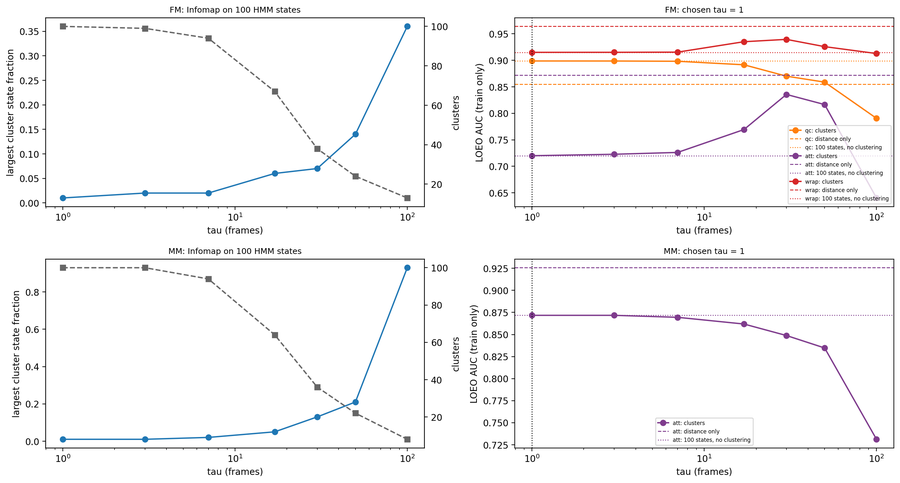

unit  tau  n_clusters  largest_cluster_state_fraction  within_nodiag  loeo_auc_qc  loeo_auc_att  loeo_auc_wrap  chosen
  FM    1         100                            0.01          0.000        0.899         0.720          0.915    True
  FM    3          99                            0.02          0.012        0.899         0.723          0.915   False
  FM    7          94                            0.02          0.046        0.898         0.726          0.915   False
  FM   17          67                            0.06          0.182        0.891         0.769          0.935   False
  FM   30          38                            0.07          0.295        0.870         0.836          0.939   False
  FM   50          24                            0.14          0.383        0.859         0.816          0.926   False
  FM  100          13                            0.36          0.579        0.790         0.640          0.913   False
  MM    1         100                           

In [7]:
# Step 4: Infomap on the K_LARGE HMM states.
L.clear_log("04")


def segments_of(st, block):
    seg = np.full(len(st), -1, np.int64)
    for i, (a, b) in enumerate(zip(*H.runs(st >= 0, block))):
        seg[a:b] = i
    return seg


def infomap_labels(st, seg, tau, n):
    counts, _np = S.transition_counts(st, seg, int(tau), n)
    c = counts.tocsr().astype(float)
    occ = (np.asarray(c.sum(axis=1)).ravel() > 0) | (np.asarray(c.sum(axis=0)).ravel() > 0)
    keep = np.flatnonzero(occ)
    sub = c[keep][:, keep].tolil()
    if not KEEP_SELF_LOOPS:
        sub.setdiag(0)
    sub = sub.tocsr()
    raw, _cl = S.run_infomap(S.row_normalize(sub), N_TRIALS, INFOMAP_SEED, INFOMAP["backend"])
    lab = np.full(n, -1, np.int64)
    lab[keep] = raw
    # renumber by frame coverage
    sf = np.bincount(st[st >= 0], minlength=n)
    k = int(raw.max()) + 1
    cover = np.bincount(lab[keep], weights=sf[keep], minlength=k)
    order = np.argsort(-cover, kind="stable")
    new = np.empty(k, np.int64)
    new[order] = np.arange(k)
    lab[keep] = new[raw]
    return lab, counts


tau_rows, TAU_BEST, CLUSTERS = [], {}, {}
for unit in UNITS:
    g = G[(unit, "train")]
    st = STATES[(unit, K_LARGE, "train")]
    seg = segments_of(st, g["block"])
    ys = {c: P4.detection_target(g["label"], c) for c in DETECT_CLASSES}
    for tau in TAU_SCAN:
        lab, counts = infomap_labels(st, seg, tau, K_LARGE)
        cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
        k = int(lab.max()) + 1
        ids, n_ids = with_nostate(cl, k)
        row = {"unit": unit, "tau": tau, "n_clusters": k,
               "largest_cluster_state_fraction": np.bincount(lab[lab >= 0]).max() / K_LARGE,
               "within_nodiag": S.within_fraction(counts, lab, drop_diagonal=True)}
        for c, y in ys.items():
            n_exp = len(np.unique(g["exp"][y == 1]))
            row[f"loeo_auc_{c}"] = (safe_auc(y, loeo_scores(ids, y, g["exp"], g["block"], n_ids, SMOOTH_FRAMES[c]))
                                    if n_exp >= 2 and (y == 1).sum() >= MIN_POS else np.nan)
        CLUSTERS[(unit, tau)] = lab
        tau_rows.append(row)
TAUS_T = pd.DataFrame(tau_rows)
for unit in UNITS:
    d = TAUS_T[TAUS_T["unit"] == unit]
    TAU_BEST[unit] = int(d.loc[d[f"loeo_auc_{SELECT_CLASS[unit]}"].idxmax(), "tau"])
    lab = CLUSTERS[(unit, TAU_BEST[unit])]
    L.save_csv(pd.DataFrame({"state": np.arange(K_LARGE), "cluster": lab}), "04", "state_clusters", unit,
               {"K": K_LARGE, "tau": TAU_BEST[unit], **PRE}, "train", verbose=False)
TAUS_T["chosen"] = [r.tau == TAU_BEST[r.unit] for r in TAUS_T.itertuples()]
L.save_csv(TAUS_T, "04", "tau_scan", "all", {"K": K_LARGE, **PRE}, "train")
L.update_params("tau_best", TAU_BEST)
large_states = SEL[SEL["K"] == K_LARGE].set_index("unit")
fig, axes = plt.subplots(len(UNITS), 2, figsize=(14, 3.8 * len(UNITS)), squeeze=False)
for r, unit in enumerate(UNITS):
    d = TAUS_T[TAUS_T["unit"] == unit]
    ax = axes[r, 0]
    ax.plot(d["tau"], d["largest_cluster_state_fraction"], "o-", label="largest cluster: states / K")
    ax2 = ax.twinx()
    ax2.plot(d["tau"], d["n_clusters"], "s--", color="0.4", label="clusters")
    ax.set_xscale("log")
    ax.set_xlabel("tau (frames)")
    ax.set_ylabel("largest cluster state fraction")
    ax2.set_ylabel("clusters")
    ax.set_title(f"{unit}: Infomap on {K_LARGE} HMM states", fontsize=9)
    ax = axes[r, 1]
    for c in DETECT_CLASSES:
        if d[f"loeo_auc_{c}"].notna().any():
            ax.plot(d["tau"], d[f"loeo_auc_{c}"], "o-", color=CLASS_COLOR[c], label=f"{c}: clusters")
            if np.isfinite(DIST_LOEO[(unit, c)]):
                ax.axhline(DIST_LOEO[(unit, c)], color=CLASS_COLOR[c], ls="--", lw=1, label=f"{c}: distance only")
            ax.axhline(large_states.loc[unit, f"loeo_auc_{c}"], color=CLASS_COLOR[c], ls=":", lw=1,
                       label=f"{c}: {K_LARGE} states, no clustering")
    ax.axvline(TAU_BEST[unit], color="k", ls=":", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("tau (frames)")
    ax.set_ylabel("LOEO AUC (train only)")
    ax.set_title(f"{unit}: chosen tau = {TAU_BEST[unit]}", fontsize=9)
    ax.legend(fontsize=6)
fig.tight_layout()
p = L.save_fig(fig, "04", "tau_scan", "all", {"K": K_LARGE, **PRE}, "train")
display(IPImage(filename=str(L.thumbs / p.name)))
print(TAUS_T.round(3).to_string(index=False))
print("chosen tau:", TAU_BEST)
L.log("04", "done")

## Step 5 — 小 K 的状态长什么样（给状态命名用）

**做什么**：所选 K 的每个 HMM 状态：训练帧占比、平均停留时间、14 个物理变量的中位数（角度用 |θ|，0 = 朝向对方）、contact 帧比例，以及（只作描述）P(qc)、P(att)、P(wrap)。

**图** `05_states`：热图，行 = 状态（按 P(qc) 或 P(att) 排序），列 = 物理变量的中位数（每列按训练集标准化后上色，格子里是实际数值）；右侧 = 帧占比和类别比例。

**输出**：`data/05_states__<unit>__K<k>…__train.csv`。

  csv data/05_states__FM__K60-sw11-rhw3__train.csv  rows 60


  fig figures/05_states__FM__K60-sw11-rhw3__train.png


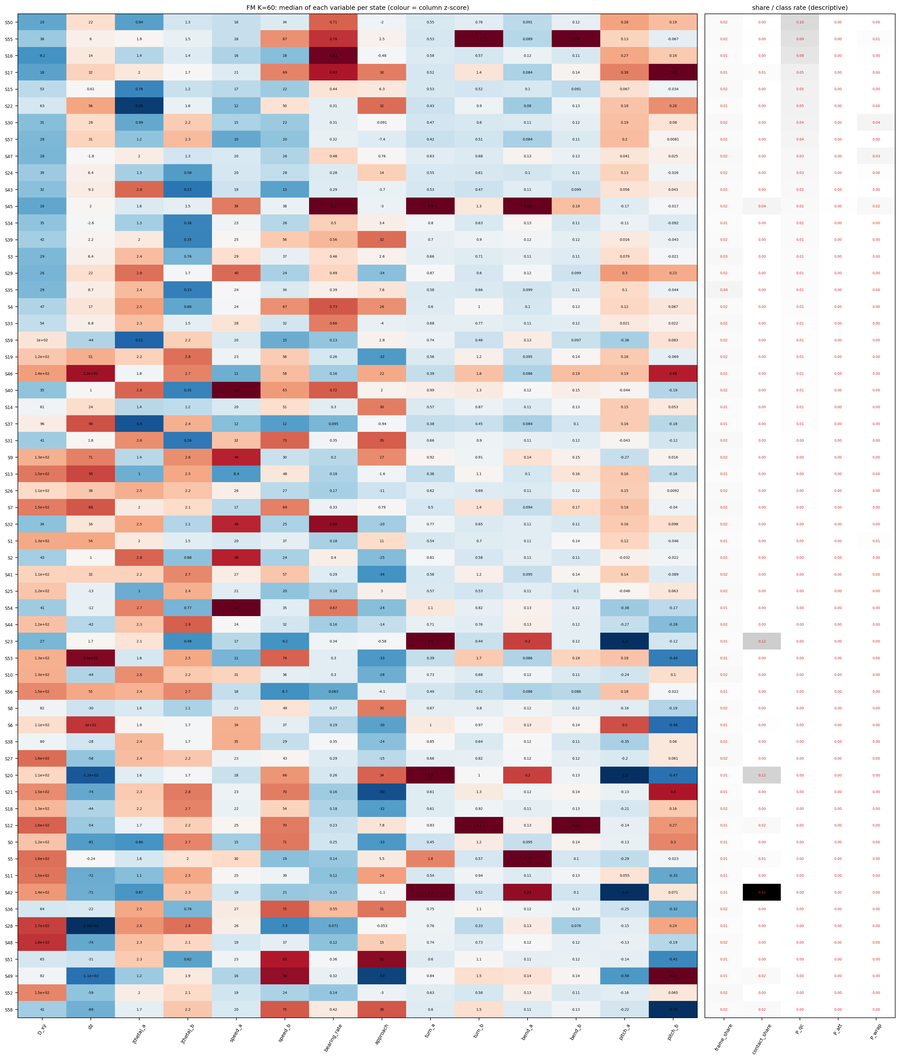

  csv data/05_states__MM__K40-sw11-rhw3__train.csv  rows 40


  fig figures/05_states__MM__K40-sw11-rhw3__train.png


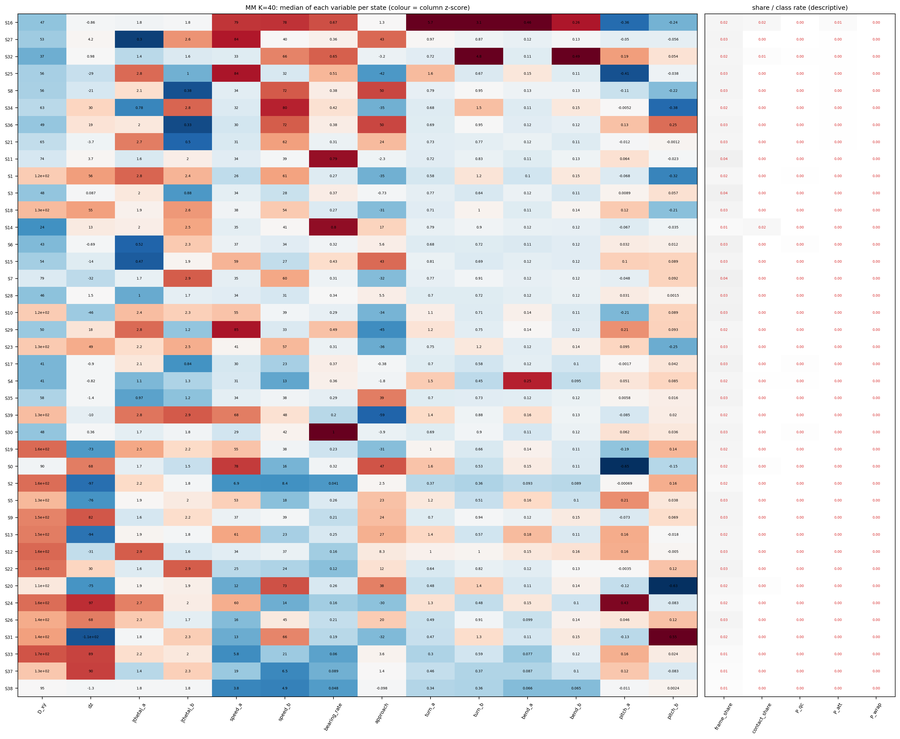

In [8]:
# Step 5: describe the states of the chosen small K.
L.clear_log("05")
STATE_TAB = {}
for unit in UNITS:
    K = K_BEST[unit]
    g = G[(unit, "train")]
    st = STATES[(unit, K, "train")]
    m = st >= 0
    v = g["vals"].astype(float)
    df = pd.DataFrame({n: v[m, j] for j, n in enumerate(VARS)})
    df["theta_a"], df["theta_b"] = np.abs(df["theta_a"]), np.abs(df["theta_b"])
    df["state"] = st[m]
    df["contact"] = g["contact"][m]
    for c in DETECT_CLASSES:
        df[f"P_{c}"] = np.where(P4.detection_target(g["label"][m], c) == 1, 1.0,
                                np.where(P4.detection_target(g["label"][m], c) == 0, 0.0, np.nan))
    tab = df.groupby("state").median(numeric_only=True)
    tab = tab.drop(columns=["contact"] + [f"P_{c}" for c in DETECT_CLASSES])
    extra = df.groupby("state").agg(frames=("state", "size"), contact_share=("contact", "mean"),
                                    **{f"P_{c}": (f"P_{c}", "mean") for c in DETECT_CLASSES})
    tab = tab.join(extra).reindex(np.arange(K))
    tab["frame_share"] = tab["frames"] / tab["frames"].sum()
    tab["mean_dwell_s"] = 1.0 / np.maximum(1 - np.diag(MODELS[(unit, K)].transmat_), 1e-9) / FPS_NOMINAL
    STATE_TAB[unit] = tab
    L.save_csv(tab.reset_index(), "05", "states", unit, {"K": K, **PRE}, "train")
    order = tab[f"P_{SELECT_CLASS[unit]}"].fillna(0).sort_values(ascending=False).index
    show = tab.loc[order, VARS]
    zc = (show - show.mean()) / show.std().replace(0, 1)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(18, 0.32 * K + 2), gridspec_kw={"width_ratios": [5, 1.4]})
    ax.imshow(zc.to_numpy(), cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
    for (i, j), val in np.ndenumerate(show.to_numpy()):
        ax.text(j, i, f"{val:.2g}", ha="center", va="center", fontsize=5)
    ax.set_xticks(np.arange(len(VARS)), [n.replace("theta", "|theta|") for n in VARS], rotation=60, fontsize=7)
    ax.set_yticks(np.arange(K), [f"S{s}" for s in order], fontsize=6)
    ax.set_title(f"{unit} K={K}: median of each variable per state (colour = column z-score)", fontsize=9)
    sub = tab.loc[order, ["frame_share", "contact_share"] + [f"P_{c}" for c in DETECT_CLASSES]]
    ax2.imshow(sub.to_numpy(dtype=float), cmap="Greys", vmin=0, vmax=max(0.3, float(np.nanmax(sub.to_numpy(dtype=float)))), aspect="auto")
    for (i, j), val in np.ndenumerate(sub.to_numpy(dtype=float)):
        ax2.text(j, i, f"{val:.2f}" if np.isfinite(val) else "", ha="center", va="center", fontsize=5, color="tab:red")
    ax2.set_xticks(np.arange(sub.shape[1]), sub.columns, rotation=60, fontsize=7)
    ax2.set_yticks([])
    ax2.set_title("share / class rate (descriptive)", fontsize=9)
    fig.tight_layout()
    p = L.save_fig(fig, "05", "states", unit, {"K": K, **PRE}, "train")
    display(IPImage(filename=str(L.thumbs / p.name)))
L.log("05", "done")

## Step 6 — 测试集评估：四种方法 × 三个类别；每个测试视频的三分类；FM1 / FM2 方向

**方法**：
- `hmm_small`：所选小 K 的 HMM 状态；
- `hmm_large_states`：K_LARGE 个 HMM 状态，不聚类；
- `hmm_large_infomap`：K_LARGE 状态 + Infomap 簇（所选 τ）；
- `distance`：3D pec 距离的 2 mm 格子（同 v3 距离基线）。

每种方法都按 v3 Step 5：训练集估计 P(c | 状态/簇)（无状态帧 = 伪状态），平滑（窗口 = 类别时长下限），训练集取 F1 最大的阈值，测试集上报告 AUC（全部帧 / 只看有状态的帧）、AP、精确率、召回率、bout 检出、报警 bout 中真的比例。三分类和 FM1 / FM2 方向同 v3 Step 5b 与候选片段 notebook（方向按所有帧上预测为 qc 的帧数）。

**图** `06_roc`（每单元 × 类别一个面板，四种方法）；`06_confusion`（每种方法：测试视频 × 配对的 3×4 混淆矩阵）。

**输出**：`data/06_detection__all__…__test.csv`、`data/06_per_video__all__…__test.csv`、`data/06_confusion__all__…__test.csv`、`data/06_fm_ratio__all__…__test.csv`。

  csv data/06_detection__all__sw11-rhw3__test.csv  rows 24
unit            method class  test_pos_frames  auc_test_smoothed  auc_test_smoothed_with_state  ap_test_smoothed  test_pos_rate  precision_test  recall_test  bouts_found_test  bouts_test  pred_bouts_correct_test  pred_bouts_test
  FM         hmm_small    qc            18305              0.907                         0.902             0.140          0.016           0.184        0.423              27.0        66.0                     76.0            330.0
  FM         hmm_small   att              132              0.843                         0.837             0.000          0.000           0.000        0.030               0.0         7.0                      1.0           1584.0
  FM         hmm_small  wrap             8616              0.902                         0.785             0.067          0.008           0.078        0.631               2.0         4.0                      8.0             80.0
  FM  hmm_large_states   

  fig figures/06_roc__all__sw11-rhw3__test.png


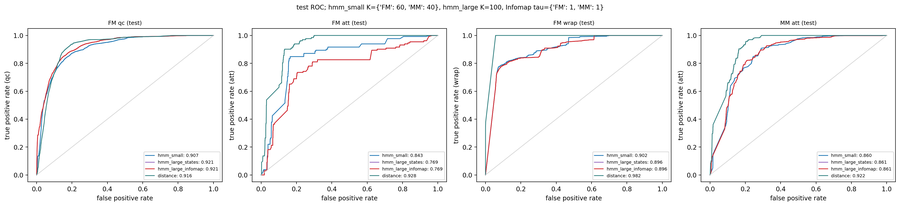

  fig figures/06_confusion_hmm_small__FM__sw11-rhw3__test.png


  fig figures/06_confusion_hmm_large_states__FM__sw11-rhw3__test.png


  fig figures/06_confusion_hmm_large_infomap__FM__sw11-rhw3__test.png


  fig figures/06_confusion_distance__FM__sw11-rhw3__test.png


  fig figures/06_confusion_hmm_small__MM__sw11-rhw3__test.png


  fig figures/06_confusion_hmm_large_states__MM__sw11-rhw3__test.png


  fig figures/06_confusion_hmm_large_infomap__MM__sw11-rhw3__test.png


  fig figures/06_confusion_distance__MM__sw11-rhw3__test.png
  csv data/06_per_video__all__sw11-rhw3__test.csv  rows 40
  csv data/06_confusion__all__sw11-rhw3__test.csv  rows 288
  csv data/06_fm_ratio__all__sw11-rhw3__test.csv  rows 8
unit            method experiment pair class  true_frames  pred_frames_all  pred_frames_labelled  precision  recall  bouts_found  bouts  pred_bouts_correct  pred_bouts  wrong_pred_bouts_per_min
  FM         hmm_small      K_1_3  FM1    qc          827             9718                  9718      0.047   0.549            2      4                   5          73                     1.943
  FM         hmm_small      K_1_3  FM1   att            0             4104                  4104      0.000   0.000            0      0                   0         486                    13.886
  FM         hmm_small      K_1_3  FM2    qc        11938            25347                 24743      0.215   0.446           20     44                  53         205              

In [9]:
# Step 6: test evaluation of the four methods.
L.clear_log("06")


def method_ids(unit, method, sn):
    g = G[(unit, sn)]
    if method == "distance":
        return distance_ids(g)
    if method == "hmm_small":
        return with_nostate(STATES[(unit, K_BEST[unit], sn)], K_BEST[unit])
    st = STATES[(unit, K_LARGE, sn)]
    if method == "hmm_large_states":
        return with_nostate(st, K_LARGE)
    lab = CLUSTERS[(unit, TAU_BEST[unit])]
    cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
    return with_nostate(cl, int(lab.max()) + 1)


METHODS = ["hmm_small", "hmm_large_states", "hmm_large_infomap", "distance"]
DET, TEST_SCORES, FITS = [], {}, {}
for unit in UNITS:
    gtr, gte = G[(unit, "train")], G[(unit, "test")]
    for method in METHODS:
        ids_tr, n_ids = method_ids(unit, method, "train")
        ids_te, _ = method_ids(unit, method, "test")
        for c in DETECT_CLASSES:
            ytr, yte = P4.detection_target(gtr["label"], c), P4.detection_target(gte["label"], c)
            row = {"unit": unit, "method": method, "class": c, "train_pos_frames": int((ytr == 1).sum()),
                   "test_pos_frames": int((yte == 1).sum()), "test_neg_frames": int((yte == 0).sum())}
            if row["train_pos_frames"] < MIN_POS or row["test_pos_frames"] < MIN_POS:
                row["note"] = f"fewer than {MIN_POS} labelled frames in train or test"
                DET.append(row)
                continue
            sc, base = fit_scores(ids_tr, ytr, n_ids)
            sm_tr = P4.rolling_mean_blocks(P4.frame_scores(ids_tr, sc, base), gtr["block"], SMOOTH_FRAMES[c])
            raw_te = P4.frame_scores(ids_te, sc, base)
            sm_te = P4.rolling_mean_blocks(raw_te, gte["block"], SMOOTH_FRAMES[c])
            thr, f1_tr = P4.best_f1_threshold(sm_tr, ytr)
            pred = sm_te >= thr
            tp, fp = int((pred & (yte == 1)).sum()), int((pred & (yte == 0)).sum())
            found, total = P4.bout_recall(yte, pred, gte["block"])
            good, n_pred = P4.bout_precision(yte, pred, gte["block"])
            okv = yte >= 0
            prec, rec = tp / max(tp + fp, 1), tp / max(row["test_pos_frames"], 1)
            row.update({"test_pos_rate": float(yte[okv].mean()), "auc_test_raw": safe_auc(yte, raw_te),
                        "auc_test_smoothed": safe_auc(yte, sm_te), "auc_test_smoothed_with_state": safe_auc(yte, sm_te, gte["ok"]),
                        "ap_test_smoothed": float(average_precision_score(yte[okv], sm_te[okv])), "threshold": thr,
                        "f1_train": f1_tr, "precision_test": prec, "recall_test": rec,
                        "f1_test": 2 * prec * rec / max(prec + rec, 1e-12), "bouts_found_test": found, "bouts_test": total,
                        "pred_bouts_correct_test": good, "pred_bouts_test": n_pred})
            DET.append(row)
            TEST_SCORES[(unit, method, c)] = (sm_te, thr)
            FITS[(unit, method, c)] = (sc, base, thr)
DET_T = pd.DataFrame(DET)
L.save_csv(DET_T, "06", "detection", "all", PRE, "test")
cols = ["unit", "method", "class", "test_pos_frames", "auc_test_smoothed", "auc_test_smoothed_with_state", "ap_test_smoothed",
        "test_pos_rate", "precision_test", "recall_test", "bouts_found_test", "bouts_test", "pred_bouts_correct_test", "pred_bouts_test"]
print(DET_T[[c for c in cols if c in DET_T.columns]].round(3).to_string(index=False))

# ROC
pairs_rc = [(u, c) for u in UNITS for c in DETECT_CLASSES if (u, "distance", c) in TEST_SCORES]
fig, axes = plt.subplots(1, len(pairs_rc), figsize=(5 * len(pairs_rc), 4.6), squeeze=False)
for ax, (unit, c) in zip(axes[0], pairs_rc):
    yte = P4.detection_target(G[(unit, "test")]["label"], c)
    for method in METHODS:
        if (unit, method, c) not in TEST_SCORES:
            continue
        s = TEST_SCORES[(unit, method, c)][0]
        okv = (yte >= 0) & np.isfinite(s)
        fpr, tpr, _t = roc_curve(yte[okv], s[okv])
        ax.plot(fpr, tpr, color=METHOD_COLOR[method], lw=1.2, label=f"{method}: {roc_auc_score(yte[okv], s[okv]):.3f}")
    ax.plot([0, 1], [0, 1], color="0.8", lw=0.8)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel(f"true positive rate ({c})")
    ax.set_title(f"{unit} {c} (test)", fontsize=9)
    ax.legend(fontsize=7, loc="lower right")
fig.suptitle(f"test ROC; hmm_small K={K_BEST}, hmm_large K={K_LARGE}, Infomap tau={TAU_BEST}", fontsize=10)
fig.tight_layout()
p = L.save_fig(fig, "06", "roc", "all", PRE, "test")
display(IPImage(filename=str(L.thumbs / p.name)))

# per video three-class, confusion, FM1 / FM2 direction
PRED_COLS = ["qc", "att", "other"]
CONF_ROWS, VID_ROWS, RATIO_ROWS = [], [], []
for unit in UNITS:
    gte = G[(unit, "test")]
    truth_all = P4.base_class(gte["label"])
    show_copies = [0, 1] if unit == "FM" else [0]
    for method in METHODS:
        src = {c: TEST_SCORES[(unit, method, c)] for c in THREE_CLASS[unit] if (unit, method, c) in TEST_SCORES}
        if not src:
            continue
        pred_all = P4.decide_classes({c: v[0] for c, v in src.items()}, {c: v[1] for c, v in src.items()})
        panels = [(ei, ci) for ei in range(len(gte["exp_names"])) for ci in show_copies]
        fig, axes = plt.subplots(1, len(panels), figsize=(4.0 * len(panels), 4.2), squeeze=False)
        qc_pred = {}
        for (ei, ci), ax in zip(panels, axes[0]):
            e, cp = gte["exp_names"][ei], gte["copy_names"][ci]
            m = (gte["exp"] == ei) & (gte["copy"] == ci)
            truth, pred = truth_all[m], pred_all[m]
            C = np.array([[int(((truth == t) & (pred == p_)).sum()) for p_ in PRED_COLS] for t in TRUTH_ROWS])
            for i, t in enumerate(TRUTH_ROWS):
                for j, p_ in enumerate(PRED_COLS):
                    CONF_ROWS.append({"unit": unit, "method": method, "experiment": exp_short(e), "pair": cp,
                                      "truth": t, "pred": p_, "frames": int(C[i, j])})
            R = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
            ax.imshow(R, cmap="Blues", vmin=0, vmax=1)
            for (i, j), val in np.ndenumerate(C):
                ax.text(j, i, f"{val}\n{100 * R[i, j]:.0f}%", ha="center", va="center", fontsize=7,
                        color="white" if R[i, j] > 0.6 else "black")
            ax.set_xticks(np.arange(3), PRED_COLS, fontsize=8)
            ax.set_yticks(np.arange(4), [f"{t} ({C[i].sum()})" for i, t in enumerate(TRUTH_ROWS)], fontsize=8)
            ax.set_title(f"{exp_short(e)} {cp}", fontsize=9)
            minutes = m.sum() / FPS[e] / 60.0
            for c in src:
                y = P4.detection_target(gte["label"][m], c)
                pc = pred == c
                found, total = P4.bout_recall(y, pc, np.zeros(len(y)))
                good, n_pred = P4.bout_precision(y, pc, np.zeros(len(y)))
                tp = int((pc & (y == 1)).sum())
                n_pc = int((pc & (y >= 0)).sum())
                VID_ROWS.append({"unit": unit, "method": method, "experiment": exp_short(e), "pair": cp, "class": c,
                                 "true_frames": int((y == 1).sum()), "pred_frames_all": int(pc.sum()), "pred_frames_labelled": n_pc,
                                 "precision": tp / max(n_pc, 1), "recall": tp / max(int((y == 1).sum()), 1),
                                 "bouts_found": found, "bouts": total, "pred_bouts_correct": good, "pred_bouts": n_pred,
                                 "wrong_pred_bouts_per_min": (n_pred - good) / max(minutes, 1e-9)})
            if unit == "FM":
                qc_pred[(e, cp)] = (int((pred == "qc").sum()), int((truth == "qc").sum()))
        fig.suptitle(f"{unit} {method}: test frames as qc / att / other (rows = BORIS)", fontsize=10)
        fig.tight_layout()
        L.save_fig(fig, "06", f"confusion_{method}", unit, PRE, "test")
        if unit == "FM":
            for e in gte["exp_names"]:
                (p1, t1), (p2, t2) = qc_pred[(e, "FM1")], qc_pred[(e, "FM2")]
                RATIO_ROWS.append({"method": method, "experiment": exp_short(e), "true_FM1": t1, "true_FM2": t2,
                                   "pred_FM1": p1, "pred_FM2": p2, "true_more": "FM1" if t1 > t2 else "FM2",
                                   "pred_more": "FM1" if p1 > p2 else "FM2",
                                   "direction_ok": (t1 > t2) == (p1 > p2),
                                   "true_ratio_FM1_over_FM2": t1 / max(t2, 1), "pred_ratio_FM1_over_FM2": p1 / max(p2, 1)})
VID_T, CONF_T, RATIO_T = pd.DataFrame(VID_ROWS), pd.DataFrame(CONF_ROWS), pd.DataFrame(RATIO_ROWS)
for t, nm in ((VID_T, "per_video"), (CONF_T, "confusion"), (RATIO_T, "fm_ratio")):
    L.save_csv(t, "06", nm, "all", PRE, "test")
print(VID_T.round(3).to_string(index=False))
print(RATIO_T.round(3).to_string(index=False))
L.log("06", "done")

## Step 7 — 行为时间线（状态按 P(类别) 上色）

`ETHOGRAM_SPECS` 中的测试片段（窗口放在该类别最密集的地方）。每个配对：
- 两行状态：`hmm_small` 的状态、`hmm_large_infomap` 的簇；**颜色 = 该状态 / 簇在训练集的 P(类别)**（白 → 深 = 越像该类别；灰 = 无状态），不再按编号上色；
- BORIS（qc 橙、att 紫、wrap 红、unknown 灰）；
- 四种方法的平滑分数与各自的阈值（虚线）。

**输出**：图 `07_ethogram_<qc|att>__<unit>__…__<实验>`。

  fig figures/07_ethogram_qc__FM__sw11-rhw3__K_1_3.png


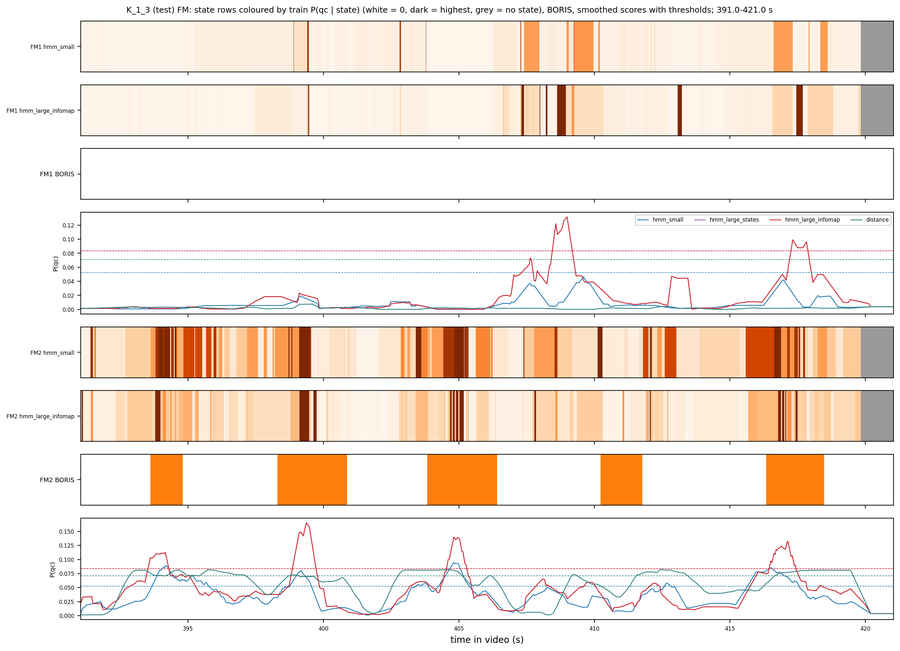

  fig figures/07_ethogram_qc__FM__sw11-rhw3__P_1_3.png


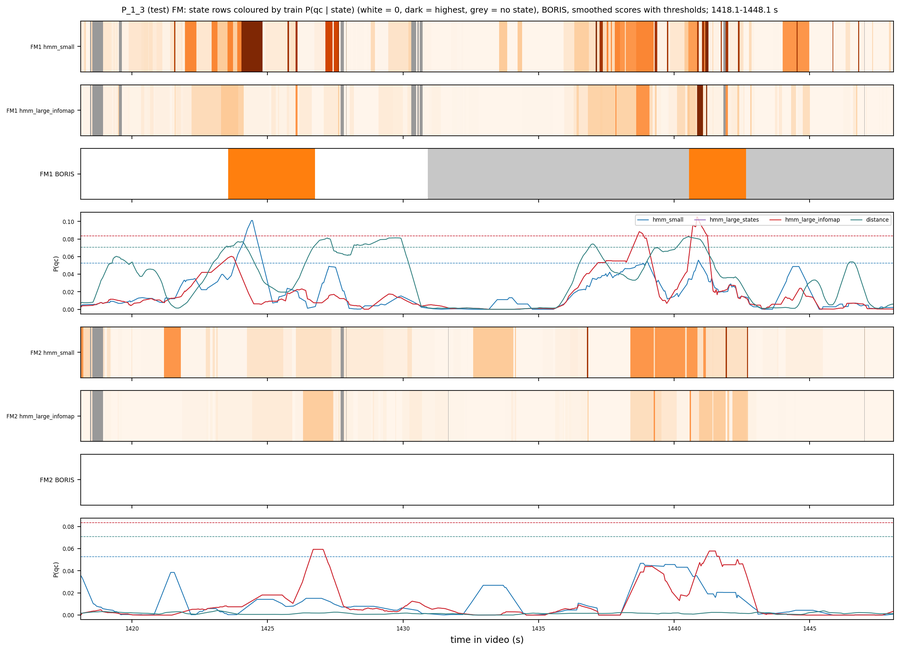

  fig figures/07_ethogram_att__MM__sw11-rhw3__K_1_3.png


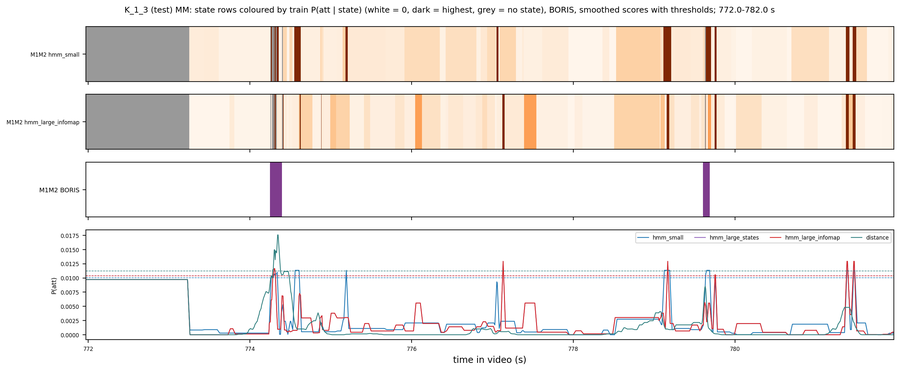

  fig figures/07_ethogram_att__MM__sw11-rhw3__P_1_3.png


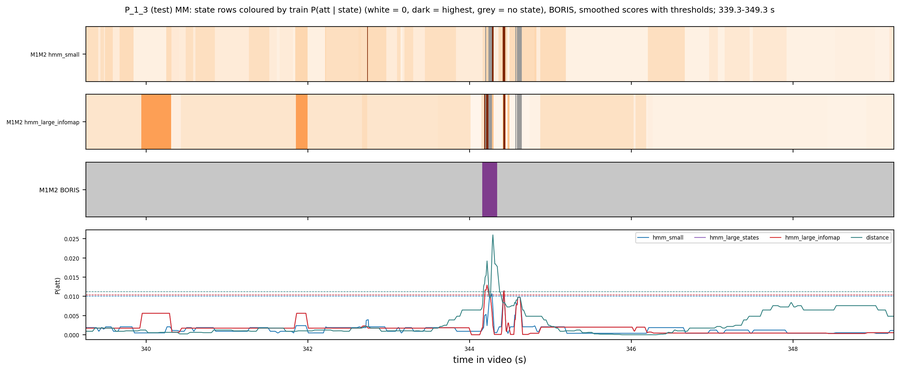

In [10]:
# Step 7: ethograms coloured by P(class | state).
from matplotlib import cm as _cm
for e, c, unit, win_s in ETHOGRAM_SPECS:
    if (unit, "hmm_small", c) not in FITS:
        continue
    gte = G[(unit, "test")]
    ei = gte["exp_names"].index(e)
    show_copies = COPIES[unit] if unit == "FM" else COPIES[unit][:1]
    fps = FPS[e]
    win = int(win_s * fps)
    n_e = len(DATA[(e, show_copies[0])]["ok"])
    dens = np.zeros(n_e)
    for cp in show_copies:
        dens += P4.base_class(FRAME_LABELS[(e, cp)]) == c
    cs = np.concatenate([[0], np.cumsum(dens)])
    sums = cs[win:] - cs[:-win]
    best = np.flatnonzero(sums == sums.max())
    start = int(best[len(best) // 2])
    t = np.arange(start, start + win) / fps
    rows_per = 4
    fig, axes = plt.subplots(rows_per * len(show_copies), 1, figsize=(14, 1.1 * rows_per * len(show_copies) + 1.4),
                             sharex=True, gridspec_kw={"height_ratios": [1, 1, 1, 2] * len(show_copies)})
    for r, cp in enumerate(show_copies):
        ci = gte["copy_names"].index(cp)
        m = np.flatnonzero((gte["exp"] == ei) & (gte["copy"] == ci))[start:start + win]
        for k, method in enumerate(("hmm_small", "hmm_large_infomap")):
            ids_te, _n = method_ids(unit, method, "test")
            sc, base, thr = FITS[(unit, method, c)]
            ids = ids_te[m]
            p_state = sc[ids]
            p_state[ids == len(sc) - 1] = np.nan    # no-state pseudo id
            ax = axes[rows_per * r + k]
            img = _cm.Oranges(np.clip(np.nan_to_num(p_state, nan=0) / max(float(np.nanmax(sc[:-1])), 1e-6), 0, 1))
            img[~np.isfinite(p_state)] = (0.6, 0.6, 0.6, 1)
            ax.imshow(img[None], aspect="auto", extent=[t[0], t[-1], 0, 1], interpolation="nearest")
            ax.set_yticks([0.5], [f"{cp} {method}"], fontsize=6)
        ax = axes[rows_per * r + 2]
        bl = P4.base_class(FRAME_LABELS[(e, cp)][start:start + win])
        for cname in list(LABEL_CLASSES) + ["unknown"]:
            a0, a1 = S.bool_runs(bl == cname)
            for s0, s1 in zip(a0, a1):
                ax.axvspan(t[s0], t[min(s1, len(t) - 1)], color=CLASS_COLOR[cname], lw=0)
        ax.set_ylim(0, 1)
        ax.set_yticks([0.5], [f"{cp} BORIS"], fontsize=7)
        ax = axes[rows_per * r + 3]
        for method in METHODS:
            if (unit, method, c) not in TEST_SCORES:
                continue
            s, thr = TEST_SCORES[(unit, method, c)]
            ax.plot(t, s[m], color=METHOD_COLOR[method], lw=0.9, label=method)
            ax.axhline(thr, color=METHOD_COLOR[method], ls="--", lw=0.6)
        if r == 0:
            ax.legend(fontsize=6, loc="upper right", ncol=4)
        ax.set_ylabel(f"P({c})", fontsize=7)
        ax.tick_params(labelsize=6)
    axes[-1].set_xlabel("time in video (s)")
    fig.suptitle(f"{exp_short(e)} (test) {unit}: state rows coloured by train P({c} | state) (white = 0, dark = highest, "
                 f"grey = no state), BORIS, smoothed scores with thresholds; {start / fps:.1f}-{(start + win) / fps:.1f} s",
                 fontsize=9)
    fig.tight_layout()
    p = L.save_fig(fig, "07", f"ethogram_{c}", unit, PRE, exp_short(e))
    display(IPImage(filename=str(L.thumbs / p.name)))

## Step 8 — 和 v3 的对比表、文件清单

把本 notebook 四种方法和 v3（`V3_RUN`，每个 τ 一行，以及 v3 的距离基线）的测试指标放在一张表里（同样的训练 / 测试划分和评估）。

**输出**：`data/08_compare_v3__all__…__test.csv`、`summary.csv`。

In [11]:
# Step 8: comparison with v3 and file listing.
cmp_cols = ["unit", "class", "method", "auc_test_smoothed", "auc_test_smoothed_with_state", "ap_test_smoothed",
            "precision_test", "recall_test", "bouts_found_test", "bouts_test", "pred_bouts_correct_test", "pred_bouts_test"]
mine = DET_T.dropna(subset=["auc_test_smoothed"]).copy()
mine["method"] = "v5_" + mine["method"]
parts = [mine[[c for c in cmp_cols if c in mine.columns]]]
v3p = OUT_ROOT / V3_RUN / "data"
v3f = sorted(v3p.glob("05_detection__all__*__test.csv")) if v3p.exists() else []
if v3f:
    v3 = pd.read_csv(v3f[0]).dropna(subset=["auc_test_smoothed"])
    v3["method"] = np.where(v3["method"] == "distance", "v3_distance", "v3_clusters_tau" + v3["tau"].fillna(0).astype(int).astype(str))
    parts.append(v3[[c for c in cmp_cols if c in v3.columns]])
CMP = pd.concat(parts, ignore_index=True).sort_values(["unit", "class", "method"])
L.save_csv(CMP, "08", "compare_v3", "all", PRE, "test")
CMP.to_csv(L.root / "summary.csv", index=False)
print(CMP.round(3).to_string(index=False))
print("\noutput folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

  csv data/08_compare_v3__all__sw11-rhw3__test.csv  rows 39
unit class               method  auc_test_smoothed  auc_test_smoothed_with_state  ap_test_smoothed  precision_test  recall_test  bouts_found_test  bouts_test  pred_bouts_correct_test  pred_bouts_test
  FM   att    v3_clusters_tau17              0.939                         0.957             0.003           0.000        0.000               0.0         7.0                      0.0              4.0
  FM   att     v3_clusters_tau3              0.936                         0.958             0.005           0.000        0.000               0.0         7.0                      0.0             16.0
  FM   att    v3_clusters_tau30              0.915                         0.927             0.002           0.000        0.000               0.0         7.0                      0.0             25.0
  FM   att    v3_clusters_tau50              0.894                         0.915             0.001           0.000        0.000             